# Part II - Deep Learning for Engineering Applications

## Task II.1 - Engineering Problem and Dataset

In [1]:
# After execution: save and close this notebook, run python refresh_part_ii_images.py, then reopen.
# See Readme: Execution Instructions. Run Part I first when its inventories or output folders are missing.
from pathlib import Path
import csv
from PIL import Image, ImageDraw, ImageFont

ROOT = Path.cwd()
if not (ROOT / 'Part_I_SVM.ipynb').is_file():
    raise RuntimeError('Set the notebook kernel’s working directory to the folder containing both notebooks and the supporting project files (for instance, working directory "draft_A").\n\nTo set it, run the following in a notebook cell before running the project code, replacing the example path with your actual folder:\nimport os\nos.chdir(r"C:\\path\\to\\draft_A")\n\nConfirm the location with:\nfrom pathlib import Path\nprint(Path.cwd())\n\n"draft_A" is only an example folder name.')


def read_records(filename):
    """Read a saved Part I CSV without changing its values or source files."""
    with (ROOT / 'data' / filename).open(encoding='utf-8', newline='') as stream:
        return list(csv.DictReader(stream))


def wrap_text(value, font, width):
    """Wrap a table value at word boundaries to fit the available pixel width."""
    lines, current = [], ''
    for word in str(value).split():
        proposed = (current + ' ' + word).strip()
        if current and font.getlength(proposed) > width:
            lines.append(current)
            current = word
        else:
            current = proposed
    return lines + [current]


def render_summary(rows, destination):
    """Render the verified summary as a readable PNG for its dedicated image cell."""
    regular = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 15)
    bold = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 15)
    title = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 18)
    small = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 13)
    widths, line_height = [248, 650], 20
    wrapped = [[wrap_text(row['item'], regular, widths[0] - 16),
                wrap_text(row['value'], regular, widths[1] - 16)] for row in rows]
    heights = [max(map(len, row)) * line_height + 12 for row in wrapped]
    image = Image.new('RGB', (sum(widths) + 32, 126 + sum(heights)), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((16, 12), 'Task II.1 - Dataset and proposed CNN inputs', font=title, fill='#172b45')
    draw.text((16, 44), 'Nb code cell 1 | Counts verified from Part I outputs', font=small, fill='#486581')
    top = 78
    for column, heading in enumerate(['Item', 'Value']):
        left = 16 + sum(widths[:column])
        draw.rectangle((left, top, left + widths[column], top + 32), fill='#203b54', outline='#d6dfe5')
        draw.text((left + 8, top + 7), heading, font=bold, fill='white')
    top += 32
    for index, (row, height) in enumerate(zip(wrapped, heights)):
        for column, lines in enumerate(row):
            left = 16 + sum(widths[:column])
            draw.rectangle((left, top, left + widths[column], top + height),
                           fill='white' if index % 2 == 0 else '#edf4f8', outline='#d6dfe5')
            for number, line in enumerate(lines):
                draw.text((left + 8, top + 6 + number * line_height), line, font=regular, fill='#172b45')
        top += height
    image.save(destination)


inventory = read_records('I2_recording_inventory.csv')
processing = read_records('I2_processing_summary.csv')
windows = read_records('I2_window_features.csv')
partitions = read_records('I3_split_inventory.csv')
recording_ids = {row['recording_id'] for row in inventory}
assert len(recording_ids) == len(inventory) == len(processing) == 40
assert {row['recording_id'] for row in processing} == recording_ids
assert {row['recording_id'] for row in windows} == recording_ids
assert {int(row['effective_fs_hz']) for row in processing} == {12000}
window_samples = 3000
assert all(int(row['windows']) == int(row['prepared_samples']) // window_samples for row in processing)
assert sum(int(row['windows']) for row in processing) == len(windows) == 1578
window_keys = {(row['recording_id'], row['window_index']) for row in windows}
assert len(window_keys) == len(windows)
assert len(partitions) == len(windows)
assert {(row['recording_id'], row['window_index']) for row in partitions} == window_keys
split_counts = {name: sum(row['partition'] == name for row in partitions)
                for name in ['training', 'validation', 'test']}
assert split_counts == {'training': 778, 'validation': 400, 'test': 400}
classes = ['normal', 'inner_race', 'ball', 'outer_race']
class_counts = {name: sum(row['condition'] == name for row in windows) for name in classes}
assert class_counts == {'normal': 138, 'inner_race': 480, 'ball': 480, 'outer_race': 480}

summary_rows = [
    {'item': 'Dataset', 'value': 'CWRU Bearing Data Center; same selected recordings as Part I'},
    {'item': 'Original recordings', 'value': str(len(recording_ids))},
    {'item': 'Derived windows', 'value': str(len(windows)) + ' (dependent within recordings)'},
    {'item': 'Classification target', 'value': 'Normal, inner-race fault, ball fault, outer-race fault'},
    {'item': 'Class window counts', 'value': 'Normal: 138; each fault class: 480'},
    {'item': 'Prepared sampling rate', 'value': '12,000 Hz'},
    {'item': 'Window duration', 'value': '0.25 seconds; non-overlapping'},
    {'item': 'Input values per window', 'value': str(window_samples) + ' acceleration samples'},
    {'item': 'Input channels', 'value': '1 (drive-end acceleration)'},
    {'item': 'Planned input layout', 'value': '(1578, 3000, 1): windows, time steps, channel'},
    {'item': 'Input preparation', 'value': 'Reuse Part I resampling, filtering and edge trimming; mean-centre each window'},
    {'item': 'Excluded predictors', 'value': 'Operating metadata and the eight engineered SVM descriptors'},
    {'item': 'Architecture selected', 'value': 'Option B: compact 1-D CNN; detailed layers and training are deferred'},
    {'item': 'Retained split counts', 'value': 'Training: 778; validation: 400; test: 400'},
    {'item': 'Implementation status', 'value': 'II.1 scope: counts verified; tensor preparation and model implementation follow in II.2'},
]
csv_path = ROOT / 'data' / 'II1_dataset_summary.csv'
with csv_path.open('w', encoding='utf-8', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=['item', 'value'])
    writer.writeheader()
    writer.writerows(summary_rows)
# The PNG is generated from the saved CSV; it is displayed once in the next image cell.
saved_summary = read_records('II1_dataset_summary.csv')
assert saved_summary == summary_rows
render_summary(saved_summary, ROOT / 'figures_of_data' / 'II1_dataset_summary.png')


We reuse CWRU drive-end vibration measurements to classify normal, inner-race, ball and outer-race bearing conditions. Forty recordings yield 1,578 non-overlapping 0.25-second windows. Each input will contain 3,000 mean-centred acceleration values at 12 kHz in one channel; operating metadata are excluded. A compact 1-D CNN uses shared temporal filters to learn local impulsive and oscillatory patterns [II.1-1]. Windows are dependent observations, not independent bearings. Part I's provenance, unresolved licence status and previously examined test results constrain interpretation.

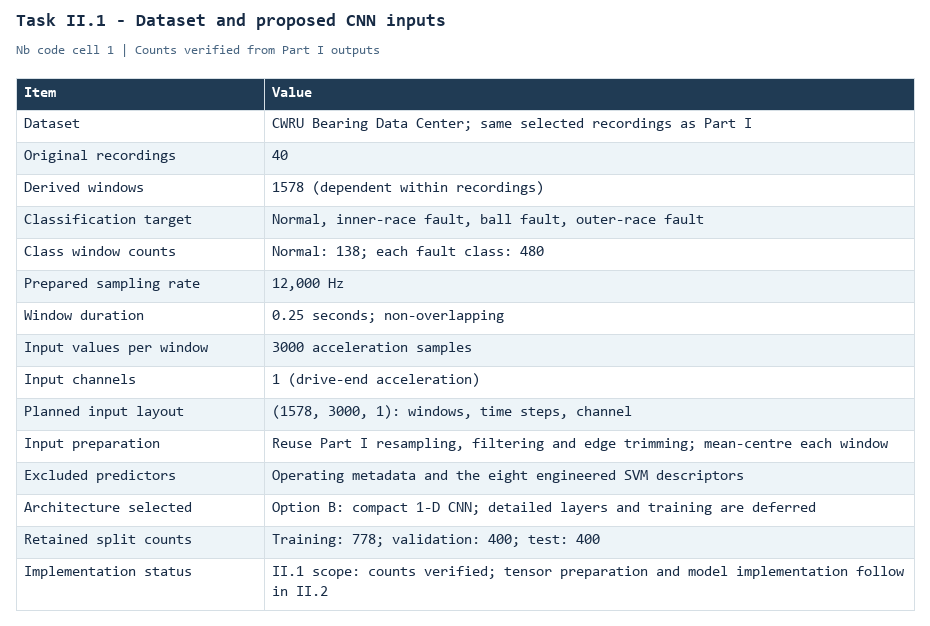

## Task II.2 - Data Preparation and Implementation

### 1. Reconstruct, partition and scale the inputs

The same cached MAT files and preparation function used in Part I produce the CNN inputs. Both notebooks import `prepare_signal()` from `signal_preparation.py`, stored alongside them, ensuring identical resampling, filtering and edge trimming. First, each file hash is checked, then the selected drive-end channel is resampled to 12 kHz where needed, low-pass filtered and trimmed at both edges. Consecutive 3,000-sample windows are reconstructed, and all 1,578 original window hashes are verified before mean removal or float32 conversion. This establishes that the CNN and SVM observations refer to the same signal segments.

Next, recording ID and window index join each observation to the fixed Part I split. Whole recordings remain together: loads 0-1 HP train the model, load 2 validates it, and load 3 is reserved for the later evaluation. Class names receive fixed integer targets. Recording, load, fault-size and quality metadata are retained for traceability, not used as predictors.

Finally, each window is mean-centred. One channel mean and population standard deviation are calculated from the 778 training windows only; those values transform all three partitions. Casting the result to float32 gives channels-last arrays with 3,000 temporal values and one channel. Using a common training scale preserves relative window amplitudes; no window is divided by its own standard deviation. Assertions check shapes, finite values, class coverage and recording/hash separation.

In [2]:
import csv
import hashlib
import json
from itertools import combinations
import numpy as np
from scipy.io import loadmat
from signal_preparation import FS, WINDOW_SAMPLES, prepare_signal

CLASS_NAMES = ['normal', 'inner_race', 'ball', 'outer_race']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
PARTITIONS = ['training', 'validation', 'test']


def sha256_file(path):
    """Fingerprint an input or saved artifact without modifying it."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


def validate_inputs(inputs, targets, membership, keys, hashes):
    """Check tensor structure, fixed membership, class coverage and partition separation."""
    assert inputs.shape == (1578, 3000, 1) and inputs.dtype == np.float32
    assert targets.shape == (1578,) and targets.dtype == np.int64
    assert np.isfinite(inputs).all() and set(targets) == set(range(4))
    assert len(set(keys)) == len(set(hashes)) == len(inputs)
    for name, expected in zip(PARTITIONS, [778, 400, 400]):
        selected = membership == name
        assert selected.sum() == expected and set(targets[selected]) == set(range(4))
    for left, right in combinations(PARTITIONS, 2):
        left_rows = np.flatnonzero(membership == left)
        right_rows = np.flatnonzero(membership == right)
        assert {keys[i][0] for i in left_rows}.isdisjoint({keys[i][0] for i in right_rows})
        assert {hashes[i] for i in left_rows}.isdisjoint({hashes[i] for i in right_rows})


recordings = read_records('I2_recording_inventory.csv')
window_inventory = read_records('I2_window_features.csv')
split_inventory = read_records('I3_split_inventory.csv')
split_lookup = {(int(row['recording_id']), int(row['window_index'])): row for row in split_inventory}
assert len(split_lookup) == len(split_inventory) == len(window_inventory) == 1578
prepared = {}
source_hashes = {}
for recording in recordings:
    recording_id = int(recording['recording_id'])
    path = ROOT / 'public_dataset' / 'recordings' / recording['local_file']
    digest = sha256_file(path)
    assert digest == recording['sha256'], f'Source file changed: {path.name}'
    contents = loadmat(path)
    raw = np.asarray(contents[recording['selected_variable']], dtype=np.float64).reshape(-1)
    assert np.isfinite(raw).all()
    assert hashlib.sha256(np.asarray(raw, dtype='<f8').tobytes()).hexdigest() == recording['signal_sha256']
    prepared[recording_id] = prepare_signal(raw, int(recording['sample_rate_hz']))
    source_hashes[recording['local_file']] = digest
assert len(prepared) == 40

waveforms, keys, window_hashes, membership, integer_targets = [], [], [], [], []
aligned_inventory = []
for row_index, row in enumerate(window_inventory):
    key = (int(row['recording_id']), int(row['window_index']))
    partition_row = split_lookup[key]
    start = key[1] * WINDOW_SAMPLES
    window = prepared[key[0]][start:start + WINDOW_SAMPLES]
    assert window.shape == (WINDOW_SAMPLES,)
    digest = hashlib.sha256(np.asarray(window, dtype='<f8').tobytes()).hexdigest()
    assert digest == row['window_sha256'] == partition_row['window_sha256']
    assert row['condition'] == partition_row['condition']
    load_hp = int(row['load_hp'])
    expected_partition = 'training' if load_hp in (0, 1) else ('validation' if load_hp == 2 else 'test')
    assert load_hp in (0, 1, 2, 3) and partition_row['partition'] == expected_partition
    waveforms.append(window)
    keys.append(key)
    window_hashes.append(digest)
    membership.append(expected_partition)
    integer_targets.append(CLASS_TO_INDEX[row['condition']])
    aligned_inventory.append(dict(row_index=row_index, recording_id=key[0], window_index=key[1],
        condition=row['condition'], target_index=integer_targets[-1], load_hp=load_hp,
        partition=expected_partition, window_sha256=digest))
assert set(keys) == set(split_lookup)

# Verify original window hashes before changing centring, scale or numeric precision.
centered = np.stack(waveforms)[:, :, None]
centered = centered - centered.mean(axis=1, keepdims=True)
membership = np.asarray(membership)
targets = np.asarray(integer_targets, dtype=np.int64)
training_mask = membership == 'training'
training_mean = float(centered[training_mask].mean(dtype=np.float64))
training_std = float(centered[training_mask].std(dtype=np.float64, ddof=0))
assert np.isfinite(training_std) and training_std > 0
inputs = ((centered - training_mean) / training_std).astype(np.float32)
validate_inputs(inputs, targets, membership, keys, window_hashes)
assert abs(float(inputs[training_mask].mean(dtype=np.float64))) < 1e-7
np.testing.assert_allclose(inputs[training_mask].std(dtype=np.float64), 1, rtol=1e-6)
assert np.max(np.abs(centered.mean(axis=1))) < 1e-10

partition_arrays = {}
partition_rows = []
for name in PARTITIONS:
    indices = np.flatnonzero(membership == name)
    partition_arrays[name] = dict(X=inputs[indices], y=targets[indices], row_index=indices)
    selected_records = [aligned_inventory[i] for i in indices]
    partition_rows.append(dict(partition=name,
        loads_hp=', '.join(map(str, sorted({row['load_hp'] for row in selected_records}))),
        recordings=len({row['recording_id'] for row in selected_records}), windows=len(indices),
        input_shape=str(partition_arrays[name]['X'].shape),
        **{label: int(np.count_nonzero(targets[indices] == index)) for index, label in enumerate(CLASS_NAMES)}))
target_rows = [dict(class_index=index, class_name=name,
    **{partition: int(np.count_nonzero(targets[membership == partition] == index)) for partition in PARTITIONS},
    all_windows=int(np.count_nonzero(targets == index))) for index, name in enumerate(CLASS_NAMES)]
preparation_rows = [
    dict(check_or_quantity='Source-file hashes', result='40 / 40 match', meaning='Original cached MAT files are unchanged.'),
    dict(check_or_quantity='Reconstructed window hashes', result='1578 / 1578 match', meaning='Identity checked before centring, scaling or float32 conversion.'),
    dict(check_or_quantity='Cross-partition shared recordings', result='0', meaning='All windows from a recording remain in one partition.'),
    dict(check_or_quantity='Cross-partition identical windows', result='0', meaning='Original window hashes are disjoint across partitions.'),
    dict(check_or_quantity='Scaling fit sample count', result=str(int(training_mask.sum()) * WINDOW_SAMPLES), meaning='Only the 778 training windows contribute acceleration samples.'),
    dict(check_or_quantity='Training channel mean', result=repr(training_mean), meaning='Computed after per-window mean removal, using float64 accumulation.'),
    dict(check_or_quantity='Training channel standard deviation', result=repr(training_std), meaning='One population standard deviation (ddof=0), reused for every partition.'),
    dict(check_or_quantity='Scaled training mean / standard deviation',
         result=f"{inputs[training_mask].mean(dtype=np.float64):.8g} / {inputs[training_mask].std(dtype=np.float64):.8g}",
         meaning='Numerically approximately zero / one; each window retains its relative amplitude.'),
    dict(check_or_quantity='Input / target dtype', result='float32 / int64', meaning='Three-dimensional waveforms and one integer class per observation.'),
    dict(check_or_quantity='Finite inputs / valid targets', result='Pass / Pass', meaning='All partitions contain finite values and the fixed target indices 0-3.'),
]
source_csv_hashes = {name: sha256_file(ROOT / 'data' / name) for name in
    ['I2_recording_inventory.csv', 'I2_window_features.csv', 'I3_split_inventory.csv']}
# Large temporary float64 arrays are no longer needed after the verified conversion.
del prepared, waveforms, centered


### 2. Build and check the CNN

A Keras Sequential model implements the two convolutional layers selected in the plan [II.2-1, II.2-2]. The first learns 16 local response patterns using 15-sample kernels and ReLU. Max pooling keeps a local maximum every four positions, reducing the sequence from 3,000 to 750 positions. The second convolution learns 32 combinations using seven-position kernels. Global average pooling summarises each feature map over time; a four-unit softmax layer produces the class probabilities [II.2-3]. The kernel settings are fixed initial design choices, not claimed optimal values.

The model is compiled with sparse categorical cross-entropy for the integer targets and Adam at a provisional learning rate of 0.001 [II.2-4]. Seed 550 and deterministic TensorFlow operations are requested. Eight training observations are passed through the initial network to check output shape, probability sums and finite loss. Weights are checked before and after this forward pass; the optimiser has made zero updates. This is an implementation check, not a training or classification result.

In [3]:
import os
import platform
import importlib.metadata
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import tensorflow as tf

SEED = 550
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()


def build_cnn():
    """Build the agreed two-convolution classifier with four class probabilities."""
    return tf.keras.Sequential([
        tf.keras.Input(shape=(3000, 1), dtype='float32', name='acceleration'),
        tf.keras.layers.Conv1D(16, 15, strides=1, padding='same', activation='relu', name='conv_local'),
        tf.keras.layers.MaxPooling1D(pool_size=4, strides=4, name='max_pool'),
        tf.keras.layers.Conv1D(32, 7, strides=1, padding='same', activation='relu', name='conv_patterns'),
        tf.keras.layers.GlobalAveragePooling1D(name='global_average'),
        tf.keras.layers.Dense(4, activation='softmax', name='bearing_condition'),
    ], name='bearing_cnn')


model = build_cnn()
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss=loss_function)
assert model.input_shape == (None, 3000, 1) and model.output_shape == (None, 4)
assert model.count_params() == sum(int(np.prod(weight.shape)) for weight in model.trainable_weights) == 4004
assert not model.non_trainable_weights and int(model.optimizer.iterations.numpy()) == 0

training_batch = partition_arrays['training']['X'][:8]
training_labels = partition_arrays['training']['y'][:8]
weights_before_check = [weight.copy() for weight in model.get_weights()]
probabilities = model(training_batch, training=False).numpy()
assert probabilities.shape == (8, 4) and np.isfinite(probabilities).all()
assert ((probabilities >= 0) & (probabilities <= 1)).all()
np.testing.assert_allclose(probabilities.sum(axis=1), 1, rtol=1e-6, atol=1e-6)
initial_batch_loss = float(loss_function(training_labels, probabilities).numpy())
assert np.isfinite(initial_batch_loss)
for before, after in zip(weights_before_check, model.get_weights()):
    np.testing.assert_array_equal(before, after)
assert int(model.optimizer.iterations.numpy()) == 0

layer_settings = {
    'conv_local': '16 filters; kernel=15; stride=1; same padding; ReLU; bias=True',
    'max_pool': 'Pool size=4; stride=4; valid padding',
    'conv_patterns': '32 filters; kernel=7; stride=1; same padding; ReLU; bias=True',
    'global_average': 'Average each of 32 feature maps across 750 temporal positions',
    'bearing_condition': '4 units; softmax; bias=True',
}
architecture_rows = [dict(layer='Input: acceleration', settings='3000 time steps; 1 acceleration channel',
                          output_shape=str(model.input_shape), trainable_parameters=0)]
for layer in model.layers:
    architecture_rows.append(dict(layer=layer.name, settings=layer_settings[layer.name],
        output_shape=str(tuple(layer.output.shape)),
        trainable_parameters=sum(int(np.prod(weight.shape)) for weight in layer.trainable_weights)))
architecture_rows.append(dict(layer='TOTAL', settings='Two Conv1D layers; no model fitting performed',
                              output_shape=str(model.output_shape), trainable_parameters=model.count_params()))
assert [row['trainable_parameters'] for row in architecture_rows] == [0, 256, 0, 3616, 0, 132, 4004]
preparation_rows += [
    dict(check_or_quantity='Training-batch forward pass', result='Pass: (8, 4)', meaning='Finite class probabilities with row sums equal to one.'),
    dict(check_or_quantity='Sparse categorical cross-entropy', result='Finite on 8 training observations', meaning='A numerical readiness check, not a model-performance result.'),
    dict(check_or_quantity='Trainable parameters', result=str(model.count_params()), meaning='Includes convolution and dense biases; independently checked per layer.'),
    dict(check_or_quantity='Optimiser updates', result='0', meaning='Initial model weights are unchanged; no fitting or test scoring has run.'),
]
runtime_versions = {'python': platform.python_version(), 'numpy': np.__version__,
    'scipy': importlib.metadata.version('scipy'), 'tensorflow': tf.__version__, 'keras': tf.keras.version(),
    'tensorflow_distribution': importlib.metadata.version('tensorflow'),
    'keras_distribution': 'keras-nightly', 'keras_distribution_version': importlib.metadata.version('keras-nightly'),
    'h5py': importlib.metadata.version('h5py')}


### 3. Save reproducible outputs

One compressed archive stores the three input/target arrays and their row indices. The aligned CSV inventory links those indices to recording/window identity and original hashes. One JSON records scaling statistics, the target mapping, seed, versions, source fingerprints and verification results. The CNN remains in memory for II.3; no initial or trained model archive is saved. Reopening the input archive verifies its tensors exactly. Run II.2 and II.3 in order within the same kernel session. After a restart, rerun II.2 to rebuild the model before training. The following CSV-backed tables document the completed preparation and architecture without duplicate display outputs.

In [4]:
def write_table_csv(name, rows):
    """Save a complete table with stable column order and unrounded stored values."""
    with (ROOT / 'data' / name).open('w', encoding='utf-8', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def render_ii2_table(name, title, widths, source_cell):
    """Render a CSV as a complete wrapped PNG without duplicating its notebook output."""
    rows = read_records(name)
    columns = list(rows[0])
    regular = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 15)
    bold = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 15)
    title_font = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 18)
    small = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 13)
    values = [[column.replace('_', ' ') for column in columns]] + [[row[column] for column in columns] for row in rows]
    wrapped = [[wrap_text(value, bold if index == 0 else regular, width - 16)
                for value, width in zip(row, widths)] for index, row in enumerate(values)]
    heights = [max(map(len, row)) * 20 + 12 for row in wrapped]
    image = Image.new('RGB', (sum(widths) + 32, 94 + sum(heights)), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((16, 12), title, font=title_font, fill='#172b45')
    source_label = f"Nb code cell{'s' if '-' in str(source_cell) else ''} {source_cell}"
    draw.text((16, 44), f'Nb code cell 4 | Source: {source_label}', font=small, fill='#486581')
    top = 78
    for index, (row, height) in enumerate(zip(wrapped, heights)):
        for column, (lines, width) in enumerate(zip(row, widths)):
            left = 16 + sum(widths[:column])
            draw.rectangle((left, top, left + width, top + height),
                fill='#203b54' if index == 0 else ('white' if index % 2 else '#edf4f8'), outline='#d6dfe5')
            for line_index, line in enumerate(lines):
                draw.text((left + 8, top + 6 + line_index * 20), line,
                    font=bold if index == 0 else regular, fill='white' if index == 0 else '#172b45')
        top += height
    image.save(ROOT / 'figures_of_data' / name.replace('.csv', '.png'))


archive_path = ROOT / 'data' / 'II2_model_inputs.npz'
np.savez_compressed(archive_path, **{f'{kind}_{name}': value
    for name, arrays in partition_arrays.items() for kind, value in arrays.items()})
with np.load(archive_path, allow_pickle=False) as saved:
    for name, arrays in partition_arrays.items():
        for kind, value in arrays.items():
            np.testing.assert_array_equal(saved[f'{kind}_{name}'], value)
write_table_csv('II2_input_inventory.csv', aligned_inventory)
preparation_rows.append(dict(check_or_quantity='Saved input archive reload', result='Pass',
    meaning='Saved tensors and row indices reproduce exactly after loading.'))

write_table_csv('II2_partition_summary.csv', partition_rows)
write_table_csv('II2_target_mapping.csv', target_rows)
write_table_csv('II2_preprocessing_checks.csv', preparation_rows)
write_table_csv('II2_architecture_summary.csv', architecture_rows)
render_ii2_table('II2_partition_summary.csv', 'Task II.2 - Input partitions and class counts',
    [120, 85, 100, 85, 180, 85, 110, 85, 110], 2)
render_ii2_table('II2_target_mapping.csv', 'Task II.2 - Target labels and class counts', [110, 160, 100, 110, 85, 120], 2)
render_ii2_table('II2_preprocessing_checks.csv', 'Task II.2 - Preparation and implementation checks', [280, 260, 580], '2-4')
render_ii2_table('II2_architecture_summary.csv', 'Task II.2 - CNN architecture summary', [235, 440, 180, 190], 3)

metadata = {
    'task': 'II.2', 'seed': SEED, 'class_to_index': CLASS_TO_INDEX, 'sampling_rate_hz': FS,
    'window_samples': WINDOW_SAMPLES, 'input_layout': 'windows, time_steps, channel',
    'input_dtype': 'float32', 'target_dtype': 'int64', 'window_mean_removal': True,
    'scaling': {'fit_partition': 'training', 'samples_used': 778 * WINDOW_SAMPLES,
                'channel_mean': training_mean, 'channel_standard_deviation': training_std, 'ddof': 0,
                'formula': '(window_mean_removed_acceleration - channel_mean) / channel_standard_deviation'},
    'partitions': partition_rows, 'hash_verification': {'source_files_matched': 40, 'windows_matched': 1578},
    'source_file_sha256': source_hashes, 'source_csv_sha256': source_csv_hashes,
    'shared_preparation_module_sha256': sha256_file(ROOT / 'signal_preparation.py'),
    'architecture': architecture_rows, 'trainable_parameters': 4004, 'optimizer_iterations': 0,
    'model_storage': 'In memory only; no model archives saved',
    'training_performed': False, 'test_predictions_or_scores_computed': False,
    'test_exposure': 'The load-3 test results were previously inspected in Part I; they do not guide this implementation.',
    'readiness_checks': {'batch_partition': 'training', 'batch_size': 8, 'initial_batch_loss': initial_batch_loss,
                         'finite_probabilities_and_loss': True, 'weights_unchanged': True, 'input_archive_reload_verified': True},
    'versions': runtime_versions,
    'saved_artifacts': {str(archive_path.relative_to(ROOT)): sha256_file(archive_path)},
}
(ROOT / 'data' / 'II2_preparation_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n', encoding='utf-8')


**Input partitions.** This table follows the actual saved tensor order: observations, temporal samples, then channel. The class counts show that the normal class remains smaller. The 1,578 windows come from 40 recordings and are not 1,578 independent bearing specimens.

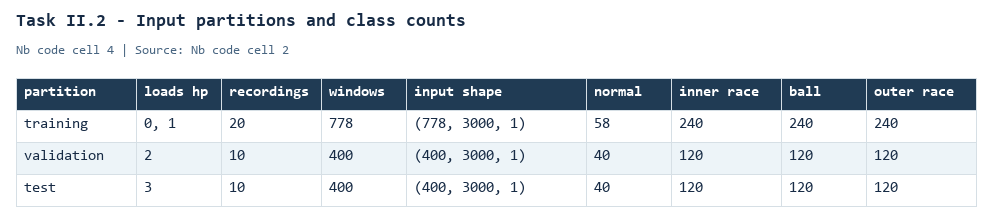

**Target labels.** The mapping is fixed before model evaluation. A target vector contains one integer per window; index 0 always denotes normal, followed by inner-race, ball and outer-race faults. The same mapping will decode the four softmax outputs in subsequent tasks.

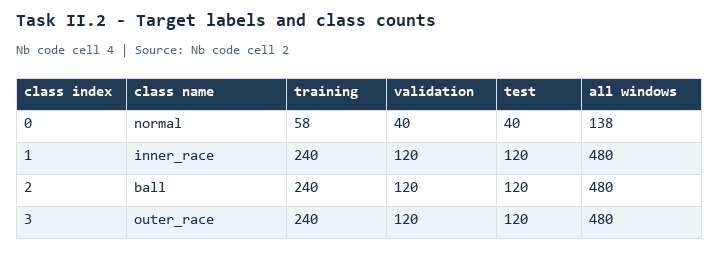

**Preparation and implementation checks.** File/window identity checks precede numerical transformations. The scaling rows report the training-derived values used for all partitions, while the final rows verify that the initial network and the saved input tensors are numerically usable. No validation/test prediction scores or trained-model results are reported.

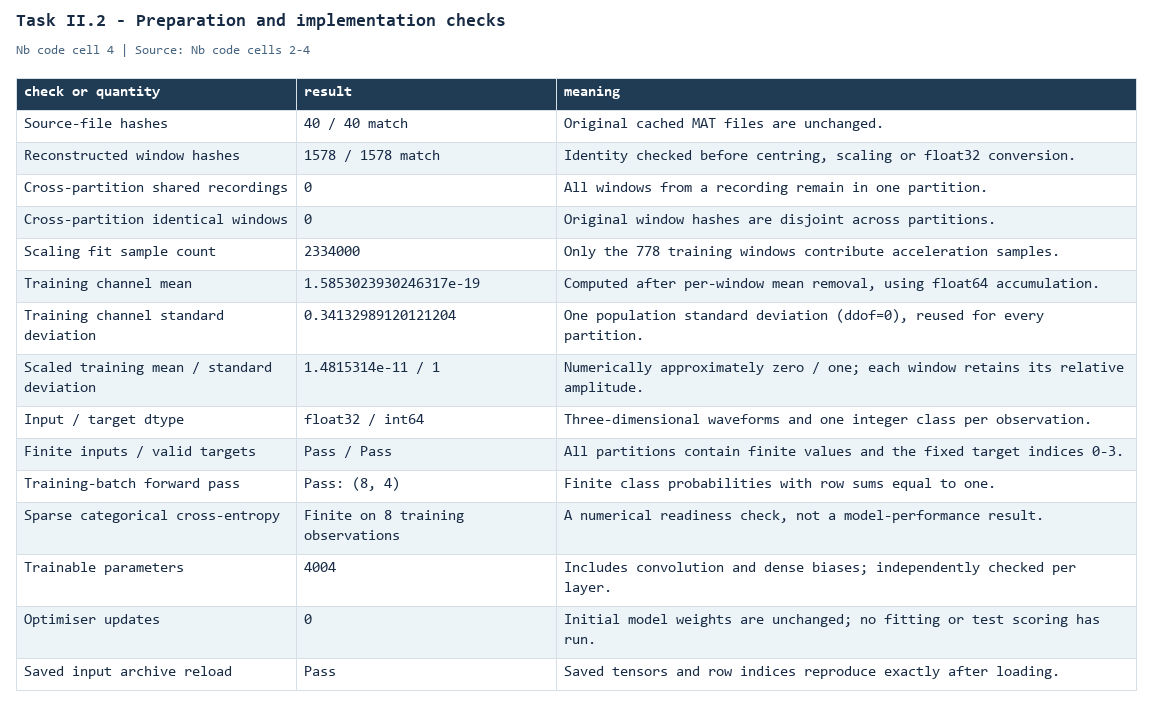

**Architecture summary.** Output shapes include an unspecified batch dimension, shown as `None`. The first convolution has `(15 x 1 + 1) x 16 = 256` parameters; the second has `(7 x 16 + 1) x 32 = 3,616`; the dense layer has `(32 + 1) x 4 = 132`. Pooling layers have no trainable parameters. Including biases, the total is **4,004**, independently checked against the built model. Global averaging avoids a large flattened classifier.

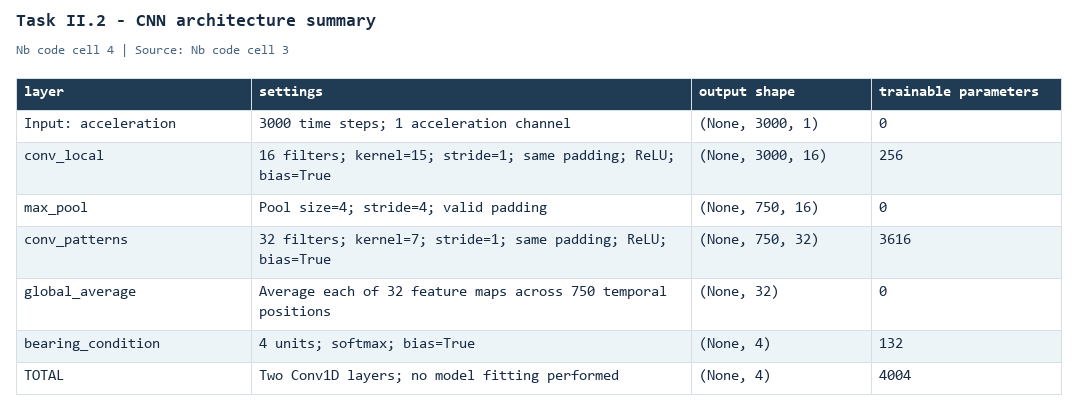

### Evaluation boundary

Macro-F1 remains the planned selection metric for later training. Part I has already exposed the load-3 test results; that partition is not newly blind, and its earlier performance does not guide these CNN settings. Shared bearing specimens, dependent windows and the single test load continue to limit generalisation. Training schedules, tuning and performance comparisons are deferred to the later tasks.

## Task II.3 - Training and Evaluation

### 1. Fix the training protocol and select a checkpoint

Training uses the untrained model created in II.2 in the same kernel session and the verified input archive. The two convolutional layers and 4,004 trainable parameters are unchanged. Only the 778 training and 400 validation windows are loaded for this step; the fixed II.2 scaling is retained. Settings are recorded before training: **Adam at 0.001, batch size 32, seed 550 and at most 100 epochs**. Training windows are shuffled within their existing partition each epoch.

Sparse categorical cross-entropy penalises low probability assigned to the correct integer-labelled class. Adam updates the weights using adaptive first- and second-moment estimates of the gradients [II.3-1, II.3-2]. Fixed class weights use training frequencies only: approximately 3.3534 for normal and 0.8104 for each fault class. This gives each class equal total weight in the training objective, without oversampling or changing the validation/test distributions.

One callback recomputes training/validation probabilities after each epoch, logs unweighted cross-entropy and macro-F1, copies the model weights into memory on a strictly higher validation macro-F1, and stops after **15 consecutive epochs without improvement**, or at epoch 100 [II.3-3]. Exact ties retain the earlier epoch. The class-weighted batch optimisation loss is logged separately; the plotted losses are both unweighted and evaluated with the same epoch-end weights, making them comparable. After stopping, the copied weights from the selected epoch are restored to the same model and its validation score verified before test access. Only weights are restored; the optimiser state belongs to the completed run and is not used again. A kernel restart discards the model, requiring rebuilding and retraining for further model evaluation. II.4 can still analyse saved predictions without the model.

In [5]:
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
import csv
import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import tensorflow as tf
from sklearn.metrics import f1_score

ROOT = Path.cwd()
SEED, MAX_EPOCHS, PATIENCE, BATCH_SIZE = 550, 100, 15, 32
CLASS_NAMES = ['normal', 'inner_race', 'ball', 'outer_race']
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()


def file_hash(path):
    """Fingerprint a saved input without modifying it."""
    return hashlib.sha256(path.read_bytes()).hexdigest()


def write_csv(path, rows):
    """Save complete records in their declared column order."""
    with path.open('w', encoding='utf-8', newline='') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def batch_probabilities(network, inputs, batch_size=128):
    """Run inference in bounded batches without constructing an additional dataset."""
    return np.concatenate([network(inputs[start:start + batch_size], training=False).numpy()
                           for start in range(0, len(inputs), batch_size)])


preparation = json.loads((ROOT / 'data/II2_preparation_metadata.json').read_text())
for name, expected_hash in preparation['saved_artifacts'].items():
    assert file_hash(ROOT / name) == expected_hash, f'II.2 artifact changed: {name}'
with np.load(ROOT / 'data/II2_model_inputs.npz', allow_pickle=False) as archive:
    X_train, y_train = archive['X_training'], archive['y_training']
    X_val, y_val = archive['X_validation'], archive['y_validation']
assert X_train.shape == (778, 3000, 1) and X_val.shape == (400, 3000, 1)
assert preparation['class_to_index'] == {name: i for i, name in enumerate(CLASS_NAMES)}
# Use the untrained model created in II.2 in this kernel session.
# Rerun II.2 before starting a fresh training run.
assert model.count_params() == 4004 and int(model.optimizer.iterations.numpy()) == 0
np.testing.assert_allclose(float(model.optimizer.learning_rate.numpy()), 0.001, rtol=1e-6)
class_counts = np.bincount(y_train, minlength=4)
class_weights = {index: float(len(y_train) / (4 * count)) for index, count in enumerate(class_counts)}
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
history_path = ROOT / 'data/II3_epoch_history.csv'
metadata_path = ROOT / 'data/II3_run_metadata.json'
run_metadata = dict(task='II.3', started_utc=datetime.now(timezone.utc).isoformat(),
    seed=SEED, maximum_epochs=MAX_EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE,
    optimizer='Adam', learning_rate=0.001, loss='sparse categorical cross-entropy',
    class_weights=class_weights, selection_metric='validation macro-F1',
    improvement_rule='strictly greater; ties retain earliest epoch',
    stop_rule='15 consecutive epochs without a strictly higher validation macro-F1, or epoch 100',
    plotted_loss='unweighted cross-entropy evaluated at epoch end in inference mode',
    model_storage='In memory only; best validation weights copied and restored before test evaluation',
    input_archive_sha256=file_hash(ROOT / 'data/II2_model_inputs.npz'),
    tensorflow_version=tf.__version__, keras_version=tf.keras.version(),
    state='settings fixed before training', test_scored=False)
metadata_path.write_text(json.dumps(run_metadata, indent=2) + '\n', encoding='utf-8')


class TrainingController(tf.keras.callbacks.Callback):
    """Log curves, copy best weights in memory and stop after patience."""
    def __init__(self):
        super().__init__()
        self.rows, self.best_score, self.best_epoch, self.wait = [], -np.inf, 0, 0
        self.best_weights = None
        self.stop_reason = 'maximum epochs reached'

    def on_epoch_end(self, epoch, logs=None):
        """Assess the completed epoch using only training and validation observations."""
        train_prob = batch_probabilities(self.model, X_train)
        val_prob = batch_probabilities(self.model, X_val)
        train_loss = float(loss_function(y_train, train_prob).numpy())
        val_loss = float(loss_function(y_val, val_prob).numpy())
        train_f1 = float(f1_score(y_train, train_prob.argmax(axis=1), labels=range(4), average='macro', zero_division=0))
        val_f1 = float(f1_score(y_val, val_prob.argmax(axis=1), labels=range(4), average='macro', zero_division=0))
        assert np.isfinite([train_loss, val_loss, train_f1, val_f1, logs['loss']]).all()
        improved = val_f1 > self.best_score
        if improved:
            self.best_score, self.best_epoch, self.wait = val_f1, epoch + 1, 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
        self.rows.append(dict(epoch=epoch + 1, weighted_optimization_loss=float(logs['loss']),
            training_loss=train_loss, validation_loss=val_loss,
            training_macro_f1=train_f1, validation_macro_f1=val_f1, new_best=bool(improved)))
        write_csv(history_path, self.rows)
        if self.wait >= PATIENCE:
            self.stop_reason = 'validation macro-F1 patience reached'
            self.model.stop_training = True
        if globals().get('II3_PROGRESS', False) and (epoch == 0 or (epoch + 1) % 5 == 0 or self.model.stop_training):
            print(f'Epoch {epoch + 1}: train F1={train_f1:.4f}; validation F1={val_f1:.4f}; best epoch={self.best_epoch}; wait={self.wait}', flush=True)


options = tf.data.Options()
options.experimental_deterministic = True
options.threading.private_threadpool_size = 1
training_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(
    len(y_train), seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE).with_options(options)
controller = TrainingController()
training_started = time.perf_counter()
model.fit(training_dataset, epochs=MAX_EPOCHS, class_weight=class_weights, callbacks=[controller], shuffle=False, verbose=0)
training_seconds = time.perf_counter() - training_started
assert controller.best_weights is not None
model.set_weights(controller.best_weights)
selected_model = model
# Only selected weights are restored; no further optimisation follows.
selected_val_prob = batch_probabilities(selected_model, X_val)
selected_val_f1 = float(f1_score(y_val, selected_val_prob.argmax(axis=1), labels=range(4), average='macro', zero_division=0))
np.testing.assert_allclose(selected_val_f1, controller.best_score, atol=1e-12, rtol=0)
for expected, actual in zip(controller.best_weights, selected_model.get_weights()):
    np.testing.assert_array_equal(expected, actual)
run_metadata.update(state='checkpoint frozen before test access', actual_epochs=len(controller.rows),
    selected_epoch=controller.best_epoch, selected_validation_macro_f1=controller.best_score,
    stopping_reason=controller.stop_reason, training_seconds=training_seconds,
    selected_weights_restored=True, test_scored=False)
metadata_path.write_text(json.dumps(run_metadata, indent=2) + '\n', encoding='utf-8')


### 2. Evaluate the frozen selected model

The selected checkpoint and all settings are frozen before the 400 test windows are loaded. A single logical inference pass supplies the predictions used for every reported test metric. Accuracy measures the fraction correctly classified. Precision measures correctness among predictions of a class; recall measures the fraction of that actual class detected; F1 is their harmonic mean. Macro averages weight the four class scores equally, and undefined scores are set to zero. No retraining, epoch reselection or parameter adjustment follows the test result.

### Evaluation metrics

This is a classification task: predictions identify normal, inner-race, ball or outer-race bearing conditions. Evaluation will therefore report accuracy, precision, recall, F1-score and a confusion matrix. MAE and RMSE apply to regression or forecasting of numerical quantities and are not applicable here. The target indices 0-3 are category labels, not measured quantities; using their numerical differences would impose an arbitrary distance between bearing conditions.

In [6]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

# Access test observations only after freezing and verifying the selected checkpoint.
assert run_metadata['state'] == 'checkpoint frozen before test access'
for expected, actual in zip(controller.best_weights, selected_model.get_weights()):
    np.testing.assert_array_equal(expected, actual)
with np.load(ROOT / 'data/II2_model_inputs.npz', allow_pickle=False) as archive:
    X_test, y_test = archive['X_test'], archive['y_test']
    test_rows = archive['row_index_test']
assert X_test.shape == (400, 3000, 1) and y_test.shape == (400,)
test_probabilities = batch_probabilities(selected_model, X_test)
assert test_probabilities.shape == (400, 4) and np.isfinite(test_probabilities).all()
np.testing.assert_allclose(test_probabilities.sum(axis=1), 1, rtol=1e-6, atol=1e-6)
test_predicted = test_probabilities.argmax(axis=1)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, test_predicted,
    labels=range(4), average='macro', zero_division=0)
overall_rows = [dict(model='CNN', accuracy=float(accuracy_score(y_test, test_predicted)),
    macro_precision=float(precision), macro_recall=float(recall), macro_f1=float(f1), test_windows=len(y_test))]
per_class = precision_recall_fscore_support(y_test, test_predicted, labels=range(4), zero_division=0)
class_rows = [dict(class_name=name, precision=float(per_class[0][i]), recall=float(per_class[1][i]),
    f1=float(per_class[2][i]), support=int(per_class[3][i])) for i, name in enumerate(CLASS_NAMES)]
test_matrix = confusion_matrix(y_test, test_predicted, labels=range(4))
assert test_matrix.sum() == 400 and np.array_equal(test_matrix.sum(axis=1), [40, 120, 120, 120])
np.testing.assert_allclose(np.trace(test_matrix) / 400, overall_rows[0]['accuracy'])
np.testing.assert_allclose(np.mean([row['f1'] for row in class_rows]), overall_rows[0]['macro_f1'])
confusion_rows = [dict(actual_class=CLASS_NAMES[i], predicted_class=CLASS_NAMES[j],
    count=int(test_matrix[i, j]), row_percentage=float(100 * test_matrix[i, j] / test_matrix[i].sum()))
    for i in range(4) for j in range(4)]
with (ROOT / 'data/II2_input_inventory.csv').open(encoding='utf-8', newline='') as stream:
    input_inventory = list(csv.DictReader(stream))
prediction_rows = []
for index, global_row in enumerate(test_rows):
    source = input_inventory[int(global_row)]
    assert source['partition'] == 'test' and int(source['target_index']) == int(y_test[index])
    prediction_rows.append(dict(row_index=int(global_row), recording_id=int(source['recording_id']),
        window_index=int(source['window_index']), actual_class=CLASS_NAMES[y_test[index]],
        predicted_class=CLASS_NAMES[test_predicted[index]],
        **{f'probability_{name}': float(test_probabilities[index, i]) for i, name in enumerate(CLASS_NAMES)}))
run_metadata.update(state='test evaluation complete; no subsequent tuning', test_scored=True,
    test_inference_passes=1, test_results=overall_rows[0],
    test_errors=int(np.count_nonzero(test_predicted != y_test)),
    test_exposure_note='Load-3 results were already examined in Part I; no test-guided CNN tuning was performed.')
for expected, actual in zip(controller.best_weights, selected_model.get_weights()):
    np.testing.assert_array_equal(expected, actual)


### 3. Save the evidence and present the results

The selected trained weights remain in memory for test evaluation; no model file is saved. One epoch-history CSV records the optimisation loss and comparable epoch-end curves; one JSON records the fixed protocol, selected epoch, stop reason, artifact fingerprints and final metrics. Separate result CSVs preserve the overall and per-class metrics, every confusion-matrix entry and aligned test predictions. Only the three main tables and two informative figures are embedded below; the prediction inventory remains a supporting CSV. Scores in metric PNGs are rounded to four decimals, while their CSVs retain full precision.

In [7]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont


def wrap_ii3_text(value, font, width):
    """Wrap text to a table column without shortening its contents."""
    result, current = [], ''
    for word in str(value).split():
        proposed = (current + ' ' + word).strip()
        if current and font.getlength(proposed) > width:
            result.append(current)
            current = word
        else:
            current = proposed
    return result + [current]


def render_ii3_table(name, title, widths, source_cell):
    """Render a CSV table, rounding metric displays only; preserve full CSV precision."""
    with (ROOT / 'data' / name).open(encoding='utf-8', newline='') as stream:
        reader = csv.DictReader(stream)
        columns, rows = list(reader.fieldnames), list(reader)
    regular = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 15)
    bold = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 15)
    heading = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 18)
    small = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 13)
    metric_columns = {'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'precision', 'recall', 'f1'}
    values = [[column.replace('_', ' ') for column in columns]]
    values += [[f'{float(row[column]):.4f}' if column in metric_columns else row[column] for column in columns] for row in rows]
    wrapped = [[wrap_ii3_text(value, bold if i == 0 else regular, width - 16)
                for value, width in zip(row, widths)] for i, row in enumerate(values)]
    heights = [max(map(len, row)) * 20 + 12 for row in wrapped]
    image = Image.new('RGB', (sum(widths) + 32, 94 + sum(heights)), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((16, 12), title, font=heading, fill='#172b45')
    draw.text((16, 44), f'Nb code cell 7 | Source: Nb code cell {source_cell}', font=small, fill='#486581')
    top = 78
    for i, (row, height) in enumerate(zip(wrapped, heights)):
        for j, (lines, width) in enumerate(zip(row, widths)):
            left = 16 + sum(widths[:j])
            draw.rectangle((left, top, left + width, top + height),
                fill='#203b54' if i == 0 else ('white' if i % 2 else '#edf4f8'), outline='#d6dfe5')
            for k, line in enumerate(lines):
                draw.text((left + 8, top + 6 + k * 20), line, font=bold if i == 0 else regular,
                          fill='white' if i == 0 else '#172b45')
        top += height
    image.save(ROOT / 'figures_of_data' / name.replace('.csv', '.png'))


summary_rows = [
    dict(item='Architecture', value='Two Conv1D layers; 4,004 trainable parameters; unchanged from II.2'),
    dict(item='Optimiser / learning rate', value='Adam / 0.001'),
    dict(item='Optimisation loss', value='Sparse categorical cross-entropy with balanced training class weights'),
    dict(item='Training class weights', value=f"Normal: {class_weights[0]:.6f}; each fault class: {class_weights[1]:.6f}"),
    dict(item='Batch size / random seed', value=f'{BATCH_SIZE} / {SEED}'),
    dict(item='Maximum epochs', value=str(MAX_EPOCHS)),
    dict(item='Selection and tie rule', value='Highest validation macro-F1; earliest exact tie; restore copied weights in memory'),
    dict(item='Stopping rule', value=f'{PATIENCE} consecutive epochs without improvement, or epoch {MAX_EPOCHS}'),
    dict(item='Completed epochs', value=str(len(controller.rows))),
    dict(item='Selected epoch', value=str(controller.best_epoch)),
    dict(item='Selected validation macro-F1', value=f'{controller.best_score:.6f}'),
    dict(item='Actual stopping reason', value=controller.stop_reason),
    dict(item='Loss learning curves', value='Unweighted training/validation cross-entropy, recomputed at epoch end'),
    dict(item='Test procedure', value='One inference pass after checkpoint selection; no subsequent tuning'),
]
write_csv(ROOT / 'data/II3_training_summary.csv', summary_rows)
write_csv(ROOT / 'data/II3_test_metrics.csv', overall_rows)
write_csv(ROOT / 'data/II3_class_metrics.csv', class_rows)
write_csv(ROOT / 'data/II3_confusion_counts.csv', confusion_rows)
write_csv(ROOT / 'data/II3_test_predictions.csv', prediction_rows)
render_ii3_table('II3_training_summary.csv', 'Task II.3 - Training and checkpoint selection', [280, 740], 5)
render_ii3_table('II3_test_metrics.csv', 'Task II.3 - Selected CNN test results', [95, 130, 165, 160, 140, 135], 6)
render_ii3_table('II3_class_metrics.csv', 'Task II.3 - Class-specific test results', [180, 130, 130, 130, 110], 6)

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def save_ii3_figure(figure, filename, title):
    """Apply the established two-line heading and spacing, then save the plot."""
    figure.suptitle(title + '\nTask II.3 | Notebook code cell 7', fontfamily='DejaVu Sans',
                   fontsize=12, fontweight='normal', linespacing=1.6)
    figure.get_layout_engine().set(h_pad=.16, w_pad=.06)
    figure.savefig(ROOT / 'figures' / filename, dpi=160, bbox_inches='tight', facecolor='white')
    plt.close(figure)


epochs = [row['epoch'] for row in controller.rows]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), layout='constrained')
for ax, train_key, val_key, title, ylabel in [
    (axes[0], 'training_loss', 'validation_loss', 'Epoch-end unweighted loss', 'Cross-entropy'),
    (axes[1], 'training_macro_f1', 'validation_macro_f1', 'Class-balanced selection metric', 'Macro-F1')]:
    ax.plot(epochs, [row[train_key] for row in controller.rows], label='Training')
    ax.plot(epochs, [row[val_key] for row in controller.rows], label='Validation')
    ax.axvline(controller.best_epoch, color='grey', linestyle=':', label='Selected epoch')
    ax.set(xlabel='Epoch', ylabel=ylabel, title=title)
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
axes[1].set_ylim(0, 1.03)
save_ii3_figure(fig, 'II3_learning_curves.png', 'CNN training and validation learning curves')

percentages = 100 * test_matrix / test_matrix.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 6.1), layout='constrained')
image = ax.imshow(percentages, vmin=0, vmax=100, cmap='Blues')
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{test_matrix[i,j]}\n({percentages[i,j]:.1f}%)', ha='center', va='center',
                fontsize=9, color='white' if percentages[i,j] > 55 else 'black')
labels = ['Normal', 'Inner race', 'Ball', 'Outer race']
ax.set_xticks(range(4), labels, rotation=35, ha='right')
ax.set_yticks(range(4), labels)
ax.set(xlabel='Predicted class', ylabel='Actual class')
fig.colorbar(image, ax=ax, label='Percentage within actual class', shrink=.85)
save_ii3_figure(fig, 'II3_confusion_matrix.png', 'Selected CNN test confusion matrix')
run_metadata['completed_utc'] = datetime.now(timezone.utc).isoformat()
metadata_path.write_text(json.dumps(run_metadata, indent=2) + '\n', encoding='utf-8')


**Training and checkpoint selection.** The run completed 46 epochs and selected epoch 31, with validation macro-F1 0.9687. Stopping occurred because validation macro-F1 did not improve for 15 consecutive epochs. Selection uses validation macro-F1 throughout; the final training epoch is not automatically the selected model.

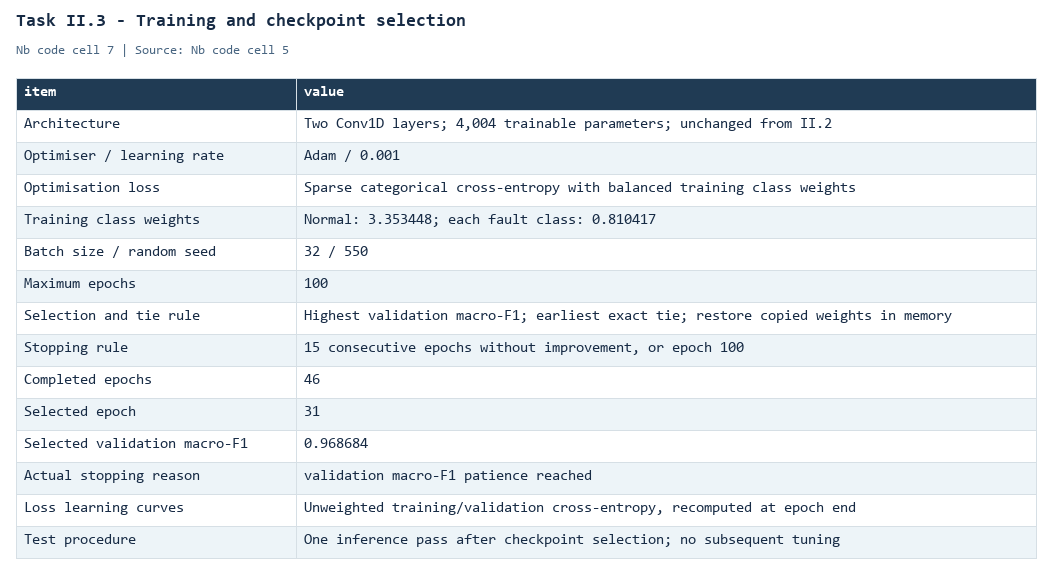

**Learning curves.** The left panel compares unweighted training and validation cross-entropy at each completed epoch; it does not mix weighted training loss with unweighted validation loss. The right panel shows macro-F1, which determines checkpoint selection and stopping. The vertical line marks the selected epoch. Loss can improve without changing the predicted classes, so a loss decrease need not raise macro-F1. A training/validation gap can reflect fitting differences and the change in operating load; it is not by itself proof of overfitting. At epoch 31 the training/validation macro-F1 values are 0.9917/0.9687; by epoch 46 they are 0.9969/0.9580. Continued training improves the training fit without exceeding the selected validation score.

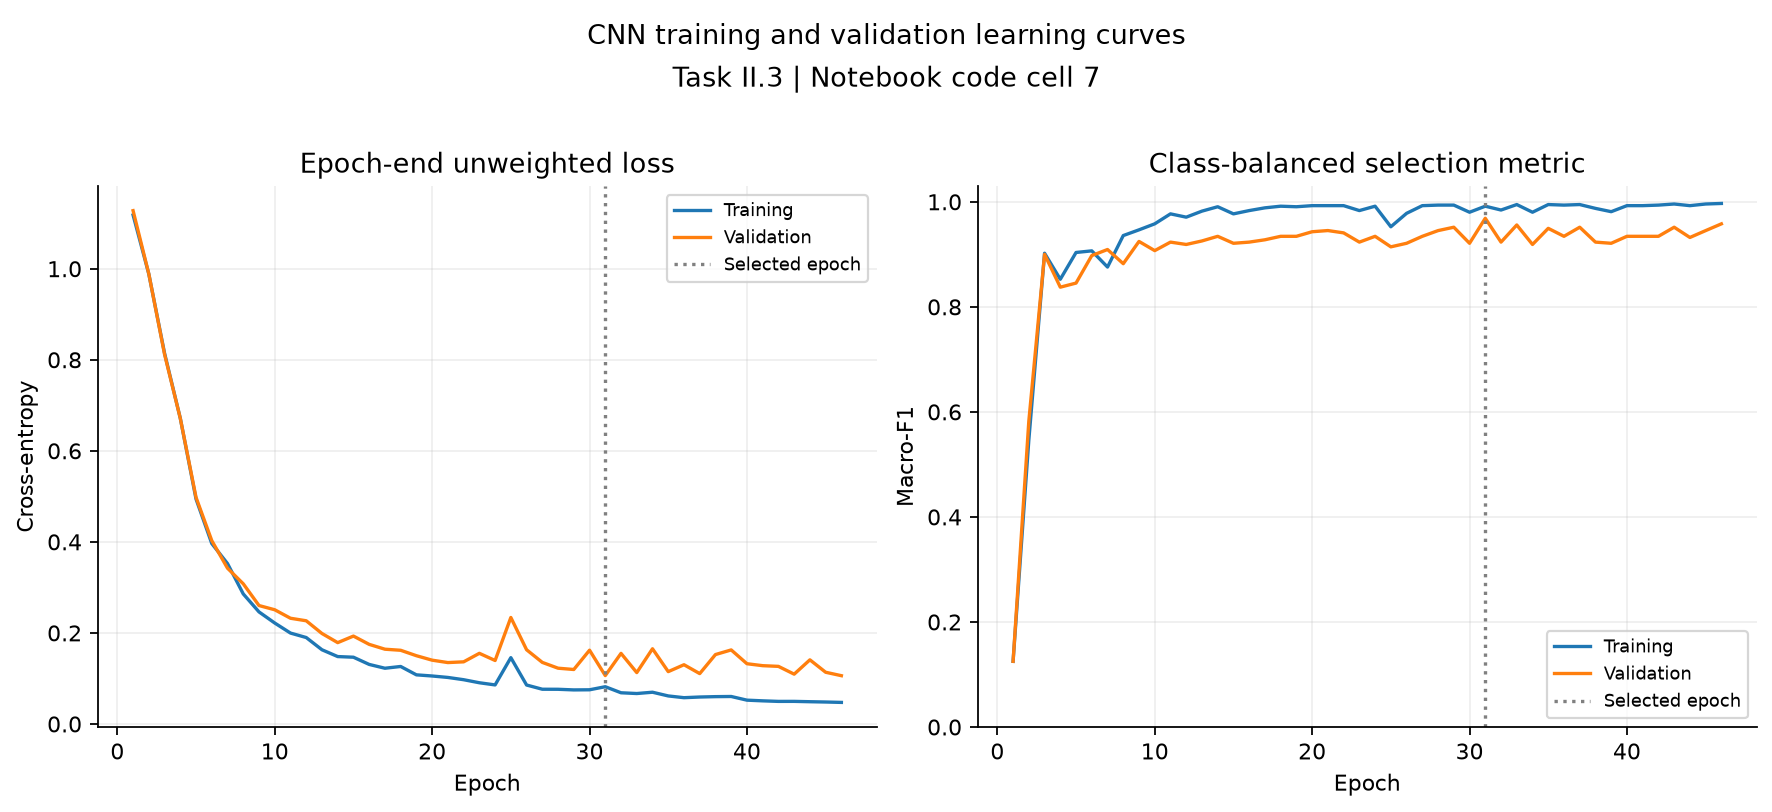

**Overall test results.** The selected CNN achieves accuracy 0.8300 and macro-F1 0.8519 on the 400 test windows (68 errors). Precision, recall and F1 are macro averages across all four classes. These results describe the frozen checkpoint on load 3 HP; they do not change the selection rule.

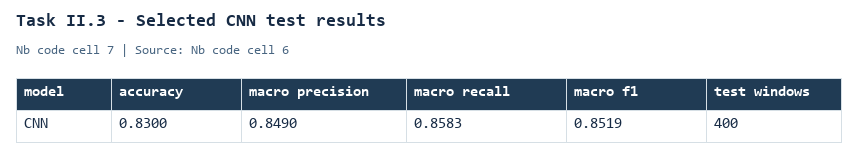

**Class-specific results.** Support counts the actual observations: 40 normal and 120 per fault class. Reading precision and recall together distinguishes missed cases from false alarms. Equal class weighting in macro-F1 makes normal-class failures visible despite its smaller support.

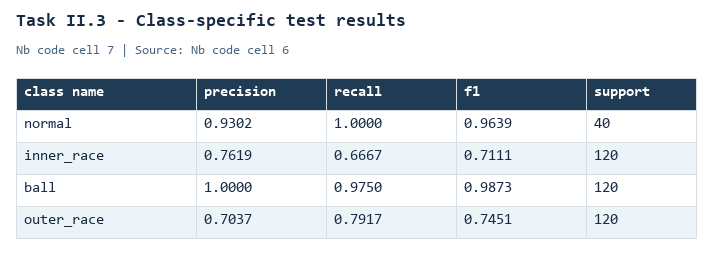

**Confusion matrix.** Rows are actual classes and columns are predictions. Each cell shows a count and its percentage within the actual class; each row therefore totals 100%. The largest confusion is inner race to outer race (40 windows). The remaining errors are 25 outer-race windows predicted as inner race and three ball windows predicted as normal.

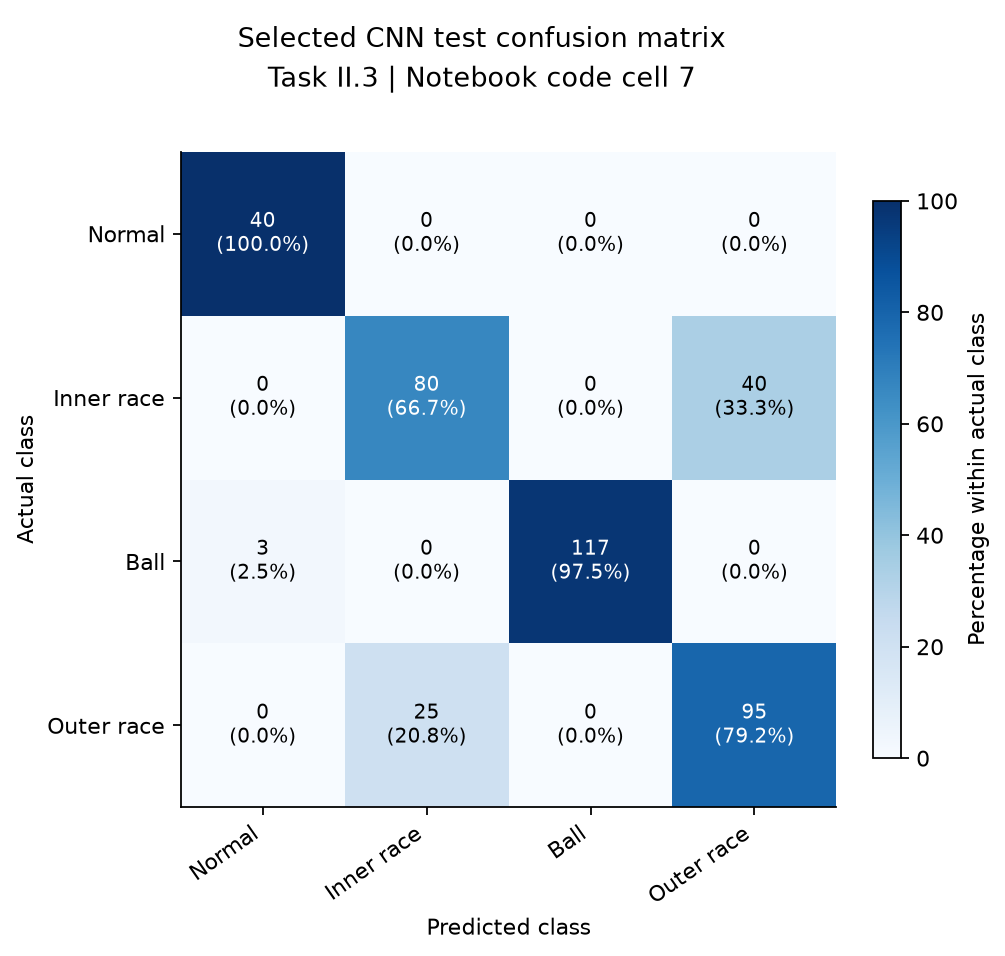

### Interpretation and limits

At the selected epoch, training macro-F1 is 0.9917 and validation macro-F1 is 0.9687; test macro-F1 is 0.8519. All 68 errors occur in three 0.014-inch fault recordings at 3 HP: recording 172 contributes 40 inner-race-to-outer-race errors, recording 200 contributes 25 outer-race-to-inner-race errors, and recording 188 contributes three ball-to-normal errors. This identifies a condition-specific weakness without establishing its cause. The test set contains only ten recordings, and windows from the same recording are dependent. Shared bearing specimens, one held-out load and previously examined Part I test results limit claims about unseen bearings or field deployment. This is one pre-specified seeded run, not a multi-seed robustness study. No test-guided tuning or post-test model replacement was performed. Sources and the AI Log are provided in Readme.

## Task II.4 - Model Behavior

### Option B - Prediction Errors

We investigate the errors using the test predictions saved in II.3. Here, **frozen predictions** means keeping those predictions and the selected epoch-31 model fixed: this analysis performs no retraining, additional inference or adjustment based on test results.

### 1. Link each prediction to its recording

Match each saved row index to the II.2 test inventory, verify its recording, window and actual class, then attach fault diameter and load from the audited recording inventory. Group all 400 predictions by recording and count incorrect labels. The error rate is `100 x errors / windows`; the final column identifies the wrong predicted classes. Include all ten recordings to show successful cases alongside failures. Source hashes verify that the analysis leaves the saved input and result files unchanged.


In [8]:
# Analyse saved predictions only: no model loading, inference or training.
from pathlib import Path
import csv
import hashlib
import json
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

ROOT = Path.cwd()
if not (ROOT / 'Part_II_CNN.ipynb').is_file():
    raise RuntimeError('Set the notebook kernel’s working directory to the folder containing both notebooks and the supporting project files (for instance, working directory "draft_A").\n\nTo set it, run the following in a notebook cell before running the project code, replacing the example path with your actual folder:\nimport os\nos.chdir(r"C:\\path\\to\\draft_A")\n\nConfirm the location with:\nfrom pathlib import Path\nprint(Path.cwd())\n\n"draft_A" is only an example folder name.')


def read_ii4_csv(name):
    with (ROOT / 'data' / name).open(encoding='utf-8-sig', newline='') as stream:
        return list(csv.DictReader(stream))


source_paths = [ROOT / 'data' / name for name in
                ['II3_test_predictions.csv', 'II3_class_metrics.csv', 'II2_input_inventory.csv',
                 'I2_recording_inventory.csv', 'II3_run_metadata.json']]
fingerprints = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                for p in source_paths}
predictions = read_ii4_csv('II3_test_predictions.csv')
inputs = {int(row['row_index']): row for row in read_ii4_csv('II2_input_inventory.csv')
          if row['partition'] == 'test'}
recordings = {int(row['recording_id']): row for row in read_ii4_csv('I2_recording_inventory.csv')}
assert len(predictions) == len(inputs) == 400
assert len({int(p['row_index']) for p in predictions}) == 400
assert {int(p['row_index']) for p in predictions} == set(inputs)
for p in predictions:
    original = inputs[int(p['row_index'])]
    assert all(p[k] == original[k] for k in ['recording_id', 'window_index'])
    assert p['actual_class'] == original['condition']
    assert original['load_hp'] == '3'
    assert p['actual_class'] == recordings[int(p['recording_id'])]['condition']

summary = []
for recording_id in sorted({int(p['recording_id']) for p in predictions}):
    rows = [p for p in predictions if int(p['recording_id']) == recording_id]
    meta = recordings[recording_id]
    wrong = Counter(p['predicted_class'] for p in rows if p['predicted_class'] != p['actual_class'])
    errors = sum(wrong.values())
    summary.append(dict(recording_id=recording_id, actual_class=meta['condition'],
                        diameter_inches=meta['diameter_inches'] or 'N/A', load_hp=int(meta['load_hp']),
                        windows=len(rows), errors=errors, error_rate_percent=100 * errors / len(rows),
                        wrong_predictions='; '.join(f'{key}: {value}' for key, value in sorted(wrong.items())) or 'None'))
assert len(summary) == 10 and sum(r['errors'] for r in summary) == 68
assert sum(r['windows'] for r in summary) == 400
assert all(r['diameter_inches'] == '0.014' for r in summary if r['errors'])
assert {r['recording_id']: r['errors'] for r in summary if r['errors']} == {172: 40, 188: 3, 200: 25}
with (ROOT / 'data/II4_recording_errors.csv').open('w', encoding='utf-8', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(summary[0]))
    writer.writeheader()
    writer.writerows(summary)

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont


def wrap_ii4_text(value, font, width):
    """Wrap text to a table column without shortening its contents."""
    result, current = [], ''
    for word in str(value).split():
        proposed = (current + ' ' + word).strip()
        if current and font.getlength(proposed) > width:
            result.append(current)
            current = word
        else:
            current = proposed
    return result + [current]


def render_ii4_table(name, title, widths, source_cell):
    """Render a CSV table, rounding metric displays only; preserve full CSV precision."""
    with (ROOT / 'data' / name).open(encoding='utf-8', newline='') as stream:
        reader = csv.DictReader(stream)
        columns, rows = list(reader.fieldnames), list(reader)
    regular = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 15)
    bold = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 15)
    heading = ImageFont.truetype('C:/Windows/Fonts/consolab.ttf', 18)
    small = ImageFont.truetype('C:/Windows/Fonts/consola.ttf', 13)
    metric_columns = {'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'precision', 'recall', 'f1'}
    values = [[column.replace('_', ' ') for column in columns]]
    values += [[f'{float(row[column]):.4f}' if column in metric_columns else row[column] for column in columns] for row in rows]
    wrapped = [[wrap_ii4_text(value, bold if i == 0 else regular, width - 16)
                for value, width in zip(row, widths)] for i, row in enumerate(values)]
    heights = [max(map(len, row)) * 20 + 12 for row in wrapped]
    image = Image.new('RGB', (sum(widths) + 32, 94 + sum(heights)), 'white')
    draw = ImageDraw.Draw(image)
    draw.text((16, 12), title, font=heading, fill='#172b45')
    draw.text((16, 44), f'Nb code cell 8 | Source: Nb code cell {source_cell}', font=small, fill='#486581')
    top = 78
    for i, (row, height) in enumerate(zip(wrapped, heights)):
        for j, (lines, width) in enumerate(zip(row, widths)):
            left = 16 + sum(widths[:j])
            draw.rectangle((left, top, left + width, top + height),
                fill='#203b54' if i == 0 else ('white' if i % 2 else '#edf4f8'), outline='#d6dfe5')
            for k, line in enumerate(lines):
                draw.text((left + 8, top + 6 + k * 20), line, font=bold if i == 0 else regular,
                          fill='white' if i == 0 else '#172b45')
        top += height
    image.save(ROOT / 'figures_of_data' / name.replace('.csv', '.png'))



render_ii4_table('II4_recording_errors.csv', 'Task II.4 - Errors by test recording',
                 [105, 145, 145, 90, 85, 80, 180, 205], 8)

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(10, 6.3), layout='constrained')
labels = [f"{r['recording_id']} | {r['actual_class'].replace('_', ' ')} | "
          + ('normal' if r['diameter_inches'] == 'N/A' else r['diameter_inches'] + ' in') for r in summary]
rates = [r['error_rate_percent'] for r in summary]
ax.barh(range(len(summary)), rates, color='#bd503d', height=.65)
ax.set_yticks(range(len(summary)), labels)
ax.invert_yaxis()
ax.set(xlabel='Misclassified windows (%)', ylabel='Test recording | condition | fault diameter', xlim=(0, 116))
ax.set_xticks([0, 25, 50, 75, 100])
ax.grid(axis='x', alpha=.2)
ax.set_axisbelow(True)
for i, row in enumerate(summary):
    ax.text(row['error_rate_percent'] + 1.5, i,
            f"{row['errors']}/{row['windows']} ({row['error_rate_percent']:g}%)", va='center', fontsize=9)
fig.suptitle('CNN prediction errors by recording (all test recordings: 3 HP)\nTask II.4 | Notebook code cell 8',
             fontfamily='DejaVu Sans', fontsize=12, fontweight='normal', linespacing=1.6)
fig.get_layout_engine().set(h_pad=.16, w_pad=.06)
fig.savefig(ROOT / 'figures/II4_recording_errors.png', dpi=160, bbox_inches='tight', facecolor='white')
plt.close(fig)

# Confirm that analysis left every prediction, input and result source unchanged.
assert all(hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest
           for name, digest in fingerprints.items())
audit = dict(task='II.4', investigation='B - Prediction Errors', source_sha256=fingerprints,
             test_windows=400, test_recordings=10, errors=68, recordings_with_errors=3,
             inner_outer_confusions=65, model_retrained=False, additional_inference=False,
             checks='Unique and complete test rows; recording/window/class alignment; source hashes unchanged')
(ROOT / 'data/II4_analysis_metadata.json').write_text(json.dumps(audit, indent=2) + '\n', encoding='utf-8')


**Recording-level results.** All recordings are held out at 3 HP, with 40 windows each. Recording 172 has 40/40 errors, recording 200 has 25/40 and recording 188 has 3/40; the other seven have none. All three failing recordings have 0.014-inch faults. `N/A` denotes a healthy bearing, for which fault diameter is undefined; `None` means no wrong predictions.


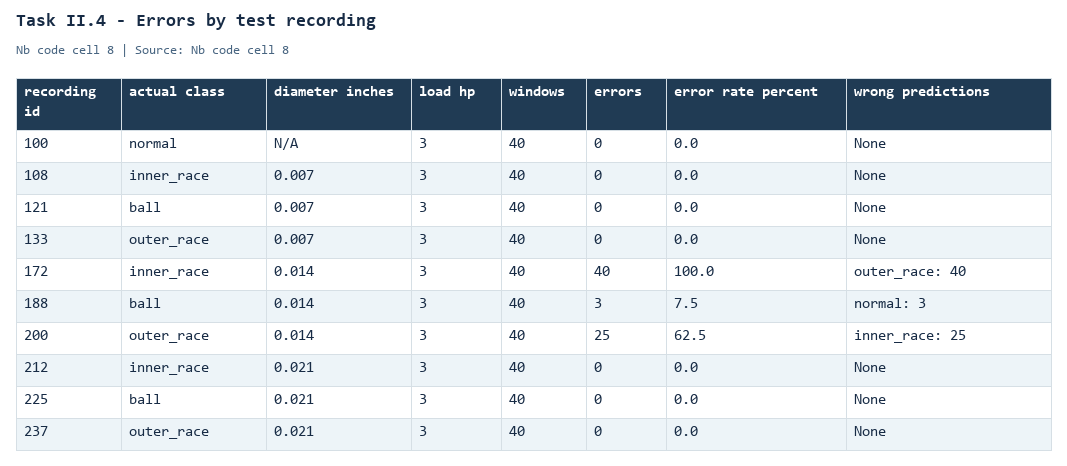

### 2. Visualise the concentration of errors

**Error rate by recording.** Each bar represents one recording, labelled by ID, condition and fault diameter. Counts beside the bars retain the denominator, including zero-error cases. This adds detail to II.3's class-level confusion matrix without repeating it: 65/68 errors (95.6%) are inner-race/outer-race confusions. Inner-race recall is 0.6667 and outer-race recall is 0.7917, compared with 1.0000 for normal and 0.9750 for ball faults.


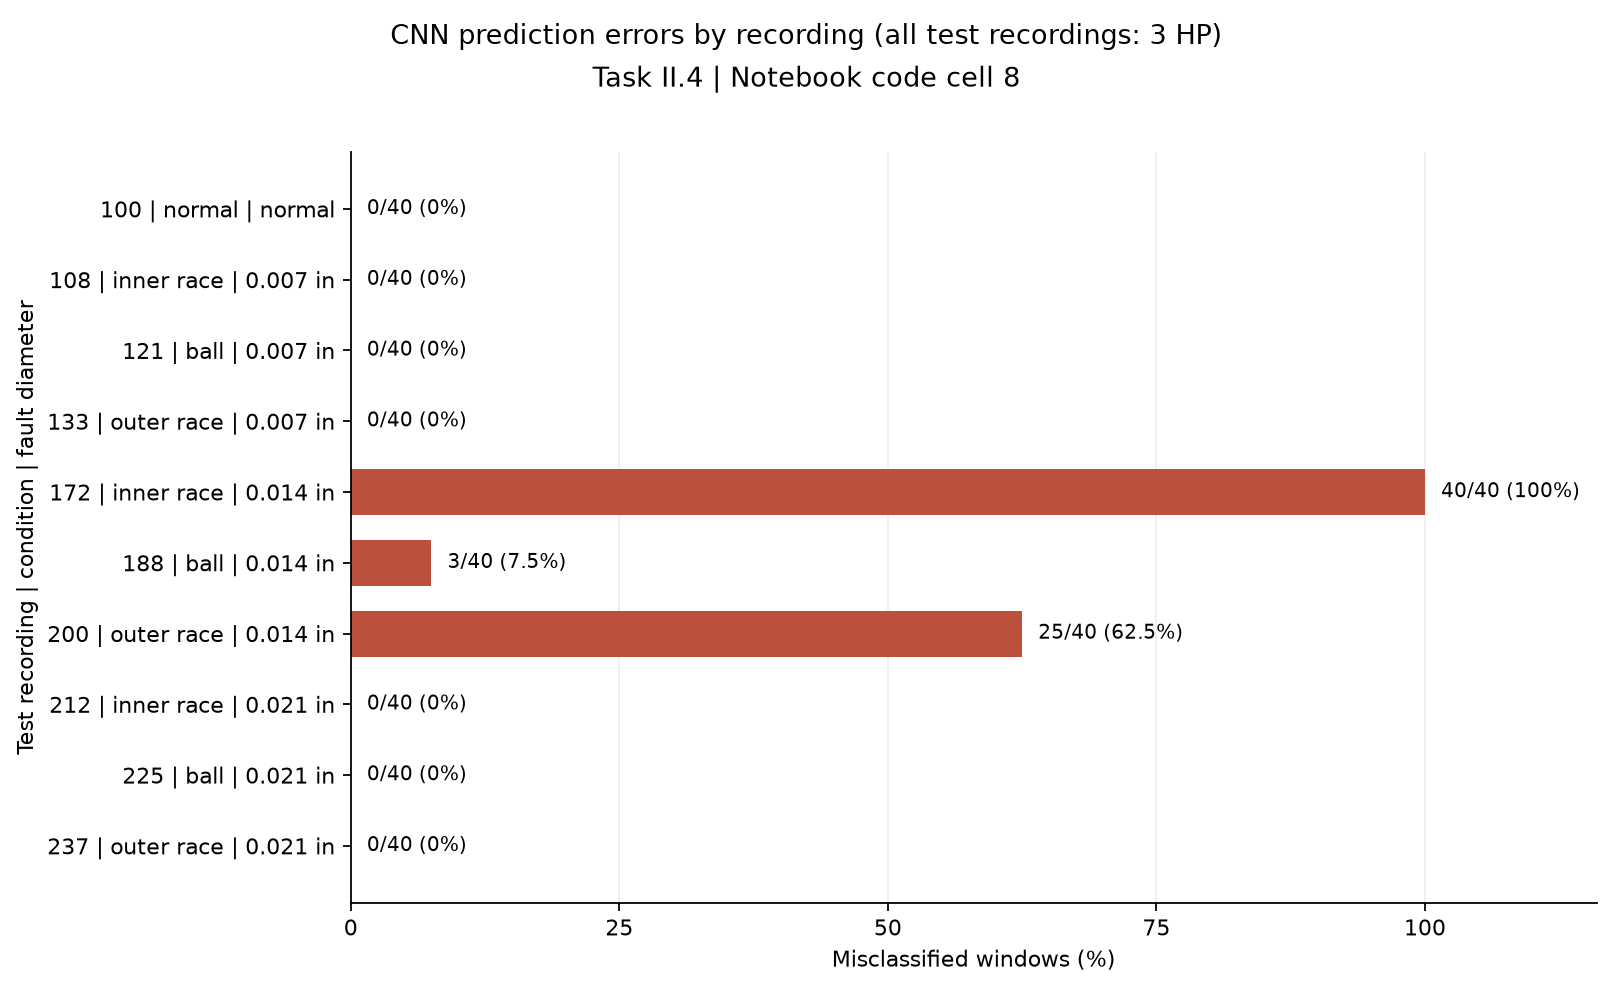

### 3. Engineering interpretation and limits

**Observed weakness.** Inner-race recording 172 is consistently classified as outer race, while 25 windows from outer-race recording 200 receive the reverse label. Three ball-fault windows from recording 188 are classified as normal. These results identify a localised failure to distinguish bearing conditions; they do not show a uniform failure across all faults or diameters.

**Possible explanations.** CWRU documents load-dependent motor speeds and the influence of outer-race fault position relative to the load zone on vibration response [II.4-1, II.4-2]. Training used loads 0-1 HP, validation 2 HP and testing 3 HP. Changes in operating conditions could therefore affect the vibration patterns learned by the CNN. However, every test recording has the same nominal load, and the selected outer-race files use the same 6 o'clock position: neither a load effect alone nor a changed outer-race position explains the concentration of errors. Load-dependent changes in the housing vibration response remain a hypothesis. A second possibility is that the compact CNN's learned features do not separate these particular inner/outer signals; global average pooling summarises local responses without retaining their full temporal arrangement. No signal-similarity or causal experiment was performed, so overlapping patterns and representation limits are possible explanations, not established causes.

**Scope of the conclusion.** Windows within a recording are dependent: 40 wrong windows from recording 172 are one recording-level failure, not 40 independent replications. All three 0.014-inch test recordings contain errors, but each condition/diameter combination has only one test recording. This cannot establish a general diameter effect. Shared specimens, one test load and one seeded training run further restrict conclusions. The evidence supports a weakness of this selected CNN on these recordings; it does not establish a limitation of CNNs generally. Test-informed analysis is used for interpretation only, with no model replacement or tuning.
